# BIKE-DYNAMICS — Tahap 1: Exploratory Data Analysis (EDA)
**Judul Penelitian:** *Pemodelan dan Simulasi Sistem Dinamik untuk Optimalisasi Ketersediaan Armada Sepeda pada Layanan Bike Sharing Berdasarkan Fluktuasi Permintaan dan Kondisi Cuaca*  
**Platform Pendamping:** `BIKE-DYNAMICS – Dynamic System Simulation for Bike Sharing Management`  
**Mata Kuliah:** Pemodelan dan Simulasi (UTS)  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/UTS-MOSI/bike-dynamics/blob/main/notebooks/01_eda_dataset.ipynb)

---
### Eksplorasi dan Pemahaman Karakteristik Dataset Bike Sharing Demand


In [1]:
# 1. Setup Lingkungan Eksekusi (Google Colab / Lokal)
import sys
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("Menjalankan di Google Colab. Memasang pustaka pendukung...")
    !pip install -q pandas numpy matplotlib seaborn scikit-learn joblib nbformat
else:
    print("Menjalankan di lingkungan lokal Python.")


Menjalankan di lingkungan lokal Python.


In [2]:
# 2. Konfigurasi Direktori Kerja & Deteksi Path Otomatis
import os
from pathlib import Path

if IN_COLAB:
    # Opsi jika menggunakan Google Drive:
    # from google.colab import drive
    # drive.mount('/content/drive')
    # PROJECT_ROOT = Path('/content/drive/MyDrive/BIKE-DYNAMICS')
    
    colab_default = Path('/content/bike-dynamics')
    colab_alt = Path('/content/BIKE-DYNAMICS-COLAB')
    colab_content = Path('/content')
    
    if (colab_default / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = colab_default
    elif (colab_alt / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = colab_alt
    elif (colab_content / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = colab_content
    elif (colab_content / 'train.csv').exists():
        PROJECT_ROOT = colab_content
        (PROJECT_ROOT / 'data' / 'raw').mkdir(parents=True, exist_ok=True)
        import shutil
        if not (PROJECT_ROOT / 'data' / 'raw' / 'train.csv').exists():
            shutil.copy(colab_content / 'train.csv', PROJECT_ROOT / 'data' / 'raw' / 'train.csv')
    else:
        PROJECT_ROOT = colab_default
        (PROJECT_ROOT / 'data' / 'raw').mkdir(parents=True, exist_ok=True)
else:
    cwd = Path.cwd()
    if (cwd / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = cwd
    elif (cwd.parent / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = cwd.parent
    else:
        PROJECT_ROOT = cwd

RAW_DATA_PATH = PROJECT_ROOT / 'data' / 'raw' / 'train.csv'
PROCESSED_DATA_PATH = PROJECT_ROOT / 'data' / 'processed' / 'cleaned_data.csv'
ARTIFACTS_DIR = PROJECT_ROOT / 'artifacts'

(PROJECT_ROOT / 'data' / 'processed').mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project Root  : {PROJECT_ROOT}")
print(f"Raw Data Path : {RAW_DATA_PATH} (Tersedia: {RAW_DATA_PATH.exists()})")


Project Root  : C:\Users\HS\Desktop\UTS MOSI (TEORI DAN PRAK) - PEMODELAN DAN SIMULASI\bike-dynamics
Raw Data Path : C:\Users\HS\Desktop\UTS MOSI (TEORI DAN PRAK) - PEMODELAN DAN SIMULASI\bike-dynamics\data\raw\train.csv (Tersedia: True)


## 1. Import Library

In [3]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi tampilan visualisasi dan pandas
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

print('Library berhasil dimuat.')

Library berhasil dimuat.


## 2. Verifikasi Folder & Load Dataset Aktual

In [4]:
# Resolusi path otomatis agar kompatibel dijalankan dari root proyek maupun folder notebooks/
cwd = Path.cwd()
if (cwd / 'data' / 'raw' / 'train.csv').exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / 'data' / 'raw' / 'train.csv').exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(
        'ERROR: File data/raw/train.csv tidak ditemukan! '
        'Pastikan dataset Kaggle Bike Sharing Demand sudah diletakkan di folder data/raw/train.csv.'
    )

RAW_DATA_PATH = PROJECT_ROOT / 'data' / 'raw' / 'train.csv'
ARTIFACTS_DIR = PROJECT_ROOT / 'artifacts'
FIGURES_DIR = ARTIFACTS_DIR / 'eda_figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df_raw = pd.read_csv(RAW_DATA_PATH)
print(f'Project Root : {PROJECT_ROOT}')
print(f'Dataset Path : {RAW_DATA_PATH}')
print('Dataset aktual berhasil dimuat!')

Project Root : C:\Users\HS\Desktop\UTS MOSI (TEORI DAN PRAK) - PEMODELAN DAN SIMULASI\bike-dynamics
Dataset Path : C:\Users\HS\Desktop\UTS MOSI (TEORI DAN PRAK) - PEMODELAN DAN SIMULASI\bike-dynamics\data\raw\train.csv
Dataset aktual berhasil dimuat!


## 3. Pemeriksaan Struktur Dataset & Rentang Waktu

In [5]:
n_rows, n_cols = df_raw.shape
print(f'Jumlah Baris : {n_rows:,}')
print(f'Jumlah Kolom : {n_cols}')
print(f'Nama Kolom   : {df_raw.columns.tolist()}')

print('\n--- Tipe Data & Info Kolom ---')
dtype_df = pd.DataFrame({
    'Kolom': df_raw.columns,
    'Tipe_Data': df_raw.dtypes.astype(str).values,
    'Jumlah_Unik': [df_raw[col].nunique() for col in df_raw.columns]
})
display(dtype_df)

# Pemeriksaan rentang waktu menggunakan salinan sementara tanpa mengubah df_raw
dt_series = pd.to_datetime(df_raw['datetime'])
print('\n--- Rentang Waktu Observasi ---')
print(f'Waktu Awal   : {dt_series.min()}')
print(f'Waktu Akhir  : {dt_series.max()}')
print(f'Hari Unik    : {sorted(dt_series.dt.day.unique().tolist())}')
print('Catatan: Pada dataset Kaggle Bike Sharing Demand, train.csv berisi data tanggal 1-19 setiap bulan.')

print('\n--- 5 Baris Pertama ---')
display(df_raw.head())

Jumlah Baris : 10,886
Jumlah Kolom : 12
Nama Kolom   : ['datetime', 'season', 'holiday', 'workingday', 'weather', 'temp', 'atemp', 'humidity', 'windspeed', 'casual', 'registered', 'count']

--- Tipe Data & Info Kolom ---


,Kolom,Tipe_Data,Jumlah_Unik
0,datetime,str,10886
1,season,int64,4
2,holiday,int64,2
3,workingday,int64,2
4,weather,int64,4
5,temp,float64,49
6,atemp,float64,60
7,humidity,int64,89
8,windspeed,float64,28
9,casual,int64,309



--- Rentang Waktu Observasi ---
Waktu Awal   : 2011-01-01 00:00:00
Waktu Akhir  : 2012-12-19 23:00:00
Hari Unik    : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
Catatan: Pada dataset Kaggle Bike Sharing Demand, train.csv berisi data tanggal 1-19 setiap bulan.

--- 5 Baris Pertama ---


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


## 4. Statistik Deskriptif & Validasi Konsistensi Target

In [6]:
desc_stats = df_raw.describe().T
desc_stats['median'] = df_raw.median(numeric_only=True)
desc_stats['skewness'] = df_raw.skew(numeric_only=True)
display(desc_stats[['count', 'mean', 'median', 'std', 'min', '25%', '50%', '75%', 'max', 'skewness']])

# Verifikasi apakah casual + registered selalu sama dengan count
consistency_diff = (df_raw['casual'] + df_raw['registered'] - df_raw['count']).abs().sum()
print(f'Total selisih |casual + registered - count| : {consistency_diff}')

,count,mean,median,std,min,25%,50%,75%,max,skewness
season,10886.0,2.506614,3.000,1.116174,1.00,2.0000,3.000,4.0000,4.0000,-0.007076
holiday,10886.0,0.028569,0.000,0.166599,0.00,0.0000,0.000,0.0000,1.0000,5.660517
workingday,10886.0,0.680875,1.000,0.466159,0.00,0.0000,1.000,1.0000,1.0000,-0.776163
weather,10886.0,1.418427,1.000,0.633839,1.00,1.0000,1.000,2.0000,4.0000,1.243484
temp,10886.0,20.230860,20.500,7.791590,0.82,13.9400,20.500,26.2400,41.0000,0.003691
atemp,10886.0,23.655084,24.240,8.474601,0.76,16.6650,24.240,31.0600,45.4550,-0.102560
humidity,10886.0,61.886460,62.000,19.245033,0.00,47.0000,62.000,77.0000,100.0000,-0.086335
windspeed,10886.0,12.799395,12.998,8.164537,0.00,7.0015,12.998,16.9979,56.9969,0.588767
casual,10886.0,36.021955,17.000,49.960477,0.00,4.0000,17.000,49.0000,367.0000,2.495748
registered,10886.0,155.552177,118.000,151.039033,0.00,36.0000,118.000,222.0000,886.0000,1.524805


Total selisih |casual + registered - count| : 0


## 5. Pemeriksaan Missing Values

In [7]:
missing_df = pd.DataFrame({
    'Missing_Count': df_raw.isnull().sum(),
    'Missing_Pct (%)': (df_raw.isnull().sum() / len(df_raw) * 100).round(4)
})
display(missing_df)
print(f'Total seluruh missing values: {int(missing_df["Missing_Count"].sum())}')

,Missing_Count,Missing_Pct (%)
datetime,0,0.0
season,0,0.0
holiday,0,0.0
workingday,0,0.0
weather,0,0.0
temp,0,0.0
atemp,0,0.0
humidity,0,0.0
windspeed,0,0.0
casual,0,0.0


Total seluruh missing values: 0


## 6. Pemeriksaan Duplikasi

In [8]:
exact_duplicates = int(df_raw.duplicated().sum())
timestamp_duplicates = int(df_raw['datetime'].duplicated().sum())

print(f'Jumlah baris duplikat identik : {exact_duplicates}')
print(f'Jumlah timestamp duplikat     : {timestamp_duplicates}')

Jumlah baris duplikat identik : 0
Jumlah timestamp duplikat     : 0


## 7. Analisis Distribusi Target (`count`)

Skewness count asli       : 1.2421
Skewness log1p(count)     : -0.8514
Persentil 95% count       : 563.75
Persentil 99% count       : 774.15


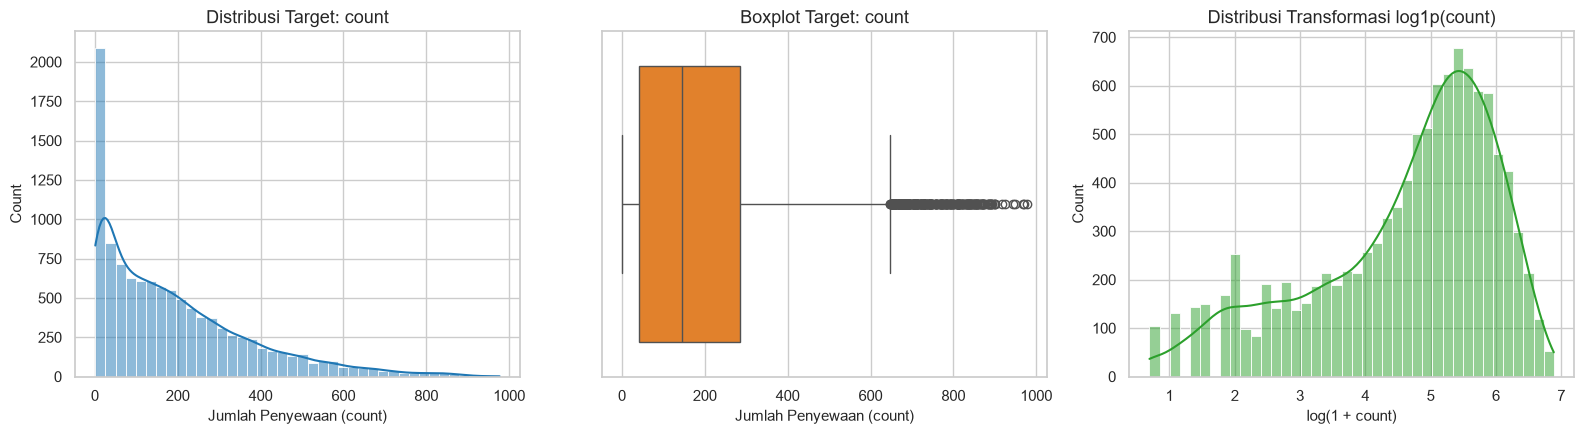

In [9]:
count_skew = float(df_raw['count'].skew())
log_count_skew = float(np.log1p(df_raw['count']).skew())

print(f'Skewness count asli       : {count_skew:.4f}')
print(f'Skewness log1p(count)     : {log_count_skew:.4f}')
print(f'Persentil 95% count       : {df_raw["count"].quantile(0.95):.2f}')
print(f'Persentil 99% count       : {df_raw["count"].quantile(0.99):.2f}')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(df_raw['count'], bins=40, kde=True, ax=axes[0], color='#1f77b4')
axes[0].set_title('Distribusi Target: count')
axes[0].set_xlabel('Jumlah Penyewaan (count)')

sns.boxplot(x=df_raw['count'], ax=axes[1], color='#ff7f0e')
axes[1].set_title('Boxplot Target: count')
axes[1].set_xlabel('Jumlah Penyewaan (count)')

sns.histplot(np.log1p(df_raw['count']), bins=40, kde=True, ax=axes[2], color='#2ca02c')
axes[2].set_title('Distribusi Transformasi log1p(count)')
axes[2].set_xlabel('log(1 + count)')

plt.tight_layout()
plt.savefig(FIGURES_DIR / '01_target_distribution.png', dpi=150)
plt.show()

## 8. Analisis Permintaan Berdasarkan Jam, Hari Kerja, dan Hari Libur

C:\Users\HS\AppData\Local\Temp\ipykernel_13832\3301898625.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  eda_df['dayofweek'] = eda_df['dt'].dt.dayofweek


count        casual        registered       
        mean median   mean median       mean median
hour                                               
0      55.14   41.0  10.31    7.0      44.83   33.0
1      33.86   19.0   6.51    4.0      27.35   15.0
2      22.90   11.0   4.82    2.0      18.08    8.0
3      11.76    6.0   2.68    1.0       9.08    5.0
4       6.41    6.0   1.26    1.0       5.14    5.0
5      19.77   19.0   1.46    1.0      18.31   18.0
6      76.26   75.0   4.15    3.0      72.11   72.0
7     213.12  208.0  10.91    9.0     202.20  201.0
8     362.77  392.0  21.54   22.0     341.23  369.0
9     221.78  217.0  30.96   26.0     190.82  182.0
10    175.09  149.0  46.12   33.0     128.97  116.0
11    210.67  183.0  60.05   43.0     150.62  139.0
12    256.51  234.5  68.83   48.0     187.68  184.0
13    257.79  226.5  74.06   50.5     183.73  179.0
14    243.44  212.0  76.59   52.0     166.85  155.5
15    254.30  232.0  76.03   54.5     178.27  175.5
16    316.37  309.5  75.08   56.5     241.29  247.0
17    468.77  480.5  75.44   63.5     393.32  374.0
18    430.86  422.5  61.40   54.0     369.46  349.0
19    315.28  312.5  49.07   41.0     266.20  259.0
20    228.52  224.0  36.73   28.0     191.79  188.5
21    173.37  171.5  28.57   22.0     144.80  144.0
22    133.58  129.0  22.60   17.0     110.97  107.0
23     89.51   80.0  15.46   11.0      74.05   68.0


--- Ringkasan Permintaan Berdasarkan Hari Kerja & Hari Libur ---


count    mean  median     std
workingday holiday                               
0          0         3163  188.77   128.0  174.27
           1          311  185.88   133.0  168.30
1          0         7412  193.01   151.0  184.51

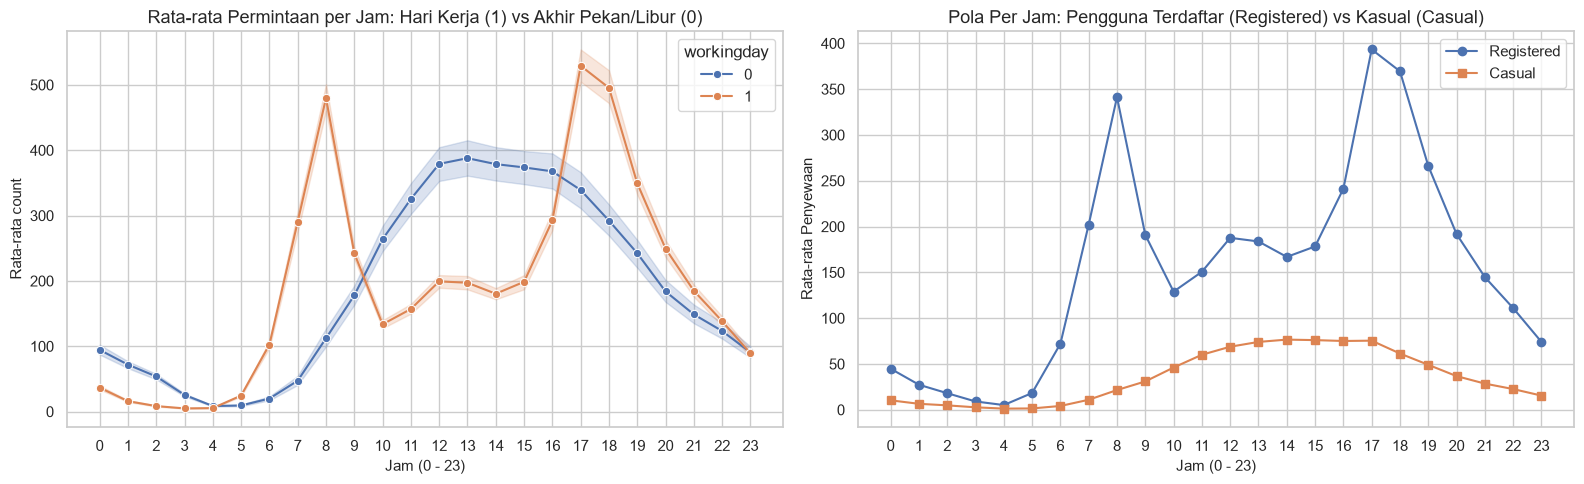

In [10]:
# Data bantu eksplorasi (tidak mengubah df_raw)
eda_df = df_raw.copy()
eda_df['dt'] = pd.to_datetime(eda_df['datetime'])
eda_df['hour'] = eda_df['dt'].dt.hour
eda_df['dayofweek'] = eda_df['dt'].dt.dayofweek

hourly_summary = eda_df.groupby('hour')[['count', 'casual', 'registered']].agg(['mean', 'median']).round(2)
display(hourly_summary)

workday_summary = eda_df.groupby(['workingday', 'holiday'])['count'].agg(['count', 'mean', 'median', 'std']).round(2)
print('\n--- Ringkasan Permintaan Berdasarkan Hari Kerja & Hari Libur ---')
display(workday_summary)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.lineplot(
    data=eda_df, x='hour', y='count', hue='workingday',
    estimator='mean', errorbar='ci', marker='o', ax=axes[0]
)
axes[0].set_title('Rata-rata Permintaan per Jam: Hari Kerja (1) vs Akhir Pekan/Libur (0)')
axes[0].set_xlabel('Jam (0 - 23)')
axes[0].set_ylabel('Rata-rata count')
axes[0].set_xticks(range(0, 24))

hourly_user_type = eda_df.groupby('hour')[['casual', 'registered']].mean().reset_index()
axes[1].plot(hourly_user_type['hour'], hourly_user_type['registered'], marker='o', label='Registered')
axes[1].plot(hourly_user_type['hour'], hourly_user_type['casual'], marker='s', label='Casual')
axes[1].set_title('Pola Per Jam: Pengguna Terdaftar (Registered) vs Kasual (Casual)')
axes[1].set_xlabel('Jam (0 - 23)')
axes[1].set_ylabel('Rata-rata Penyewaan')
axes[1].set_xticks(range(0, 24))
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / '02_hourly_workday_patterns.png', dpi=150)
plt.show()

## 9. Analisis Permintaan Berdasarkan Musim (`season`)

,count,mean,median,std
season_label,,,,
1: Spring (Semi),2686,116.34,78.0,125.27
2: Summer (Panas),2733,215.25,172.0,192.01
3: Fall (Gugur),2733,234.42,195.0,197.15
4: Winter (Dingin),2734,198.99,161.0,177.62


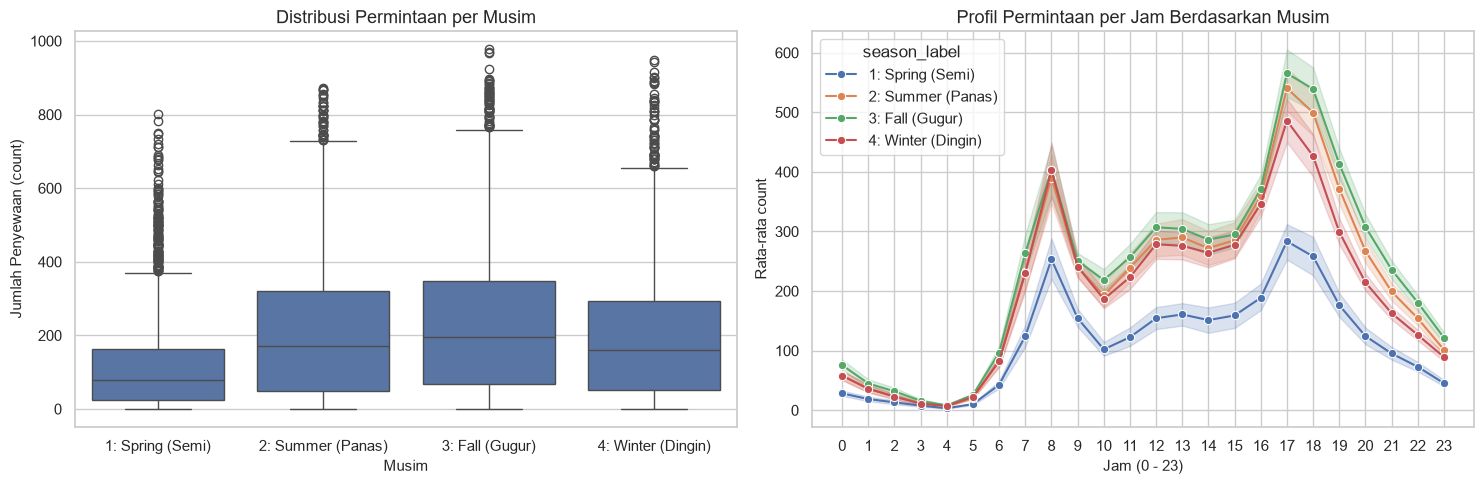

In [11]:
season_labels = {
    1: '1: Spring (Semi)',
    2: '2: Summer (Panas)',
    3: '3: Fall (Gugur)',
    4: '4: Winter (Dingin)'
}
eda_df['season_label'] = eda_df['season'].map(season_labels)

season_stats = eda_df.groupby('season_label')['count'].agg(['count', 'mean', 'median', 'std']).round(2)
display(season_stats)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=eda_df, x='season_label', y='count', ax=axes[0])
axes[0].set_title('Distribusi Permintaan per Musim')
axes[0].set_xlabel('Musim')
axes[0].set_ylabel('Jumlah Penyewaan (count)')

sns.lineplot(data=eda_df, x='hour', y='count', hue='season_label', marker='o', ax=axes[1])
axes[1].set_title('Profil Permintaan per Jam Berdasarkan Musim')
axes[1].set_xlabel('Jam (0 - 23)')
axes[1].set_ylabel('Rata-rata count')
axes[1].set_xticks(range(0, 24))

plt.tight_layout()
plt.savefig(FIGURES_DIR / '03_season_analysis.png', dpi=150)
plt.show()

## 10. Analisis Permintaan Berdasarkan Kondisi Cuaca (`weather`)

,count,mean,median,std
weather_label,,,,
1: Clear / Partly Cloudy,7192,205.24,161.0,187.96
2: Mist / Cloudy,2834,178.96,134.0,168.37
3: Light Snow / Rain,859,118.85,71.0,138.58
4: Heavy Rain / Ice,1,164.00,164.0,NaN


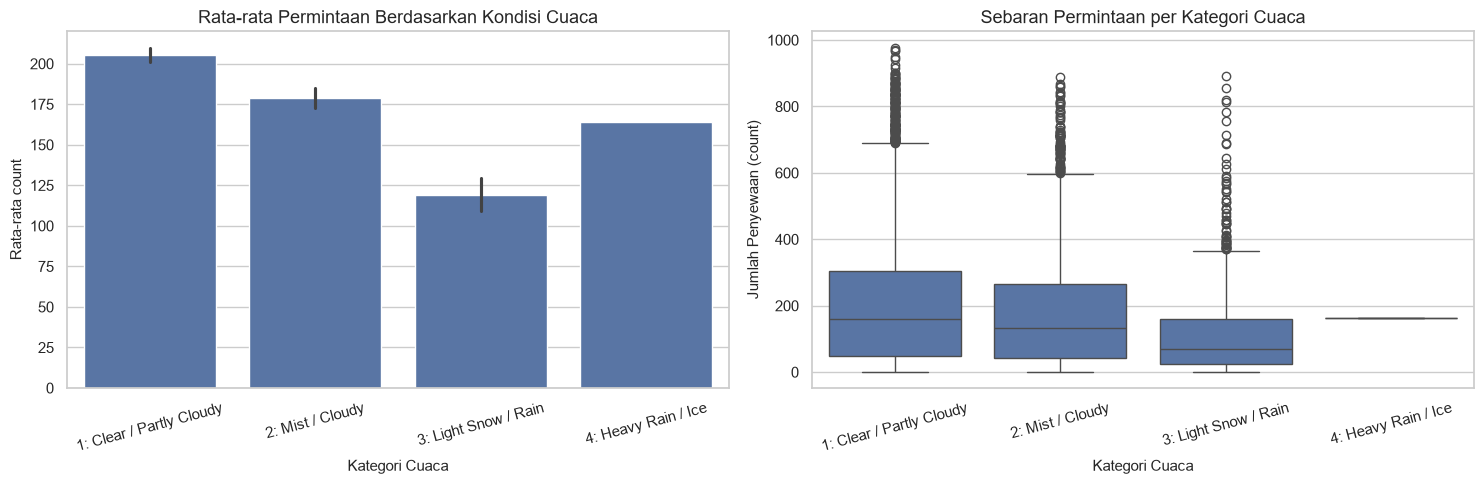

In [12]:
weather_labels = {
    1: '1: Clear / Partly Cloudy',
    2: '2: Mist / Cloudy',
    3: '3: Light Snow / Rain',
    4: '4: Heavy Rain / Ice'
}
eda_df['weather_label'] = eda_df['weather'].map(weather_labels)

weather_stats = eda_df.groupby('weather_label')['count'].agg(['count', 'mean', 'median', 'std']).round(2)
display(weather_stats)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=eda_df, x='weather_label', y='count', estimator='mean', errorbar='ci', ax=axes[0])
axes[0].set_title('Rata-rata Permintaan Berdasarkan Kondisi Cuaca')
axes[0].set_xlabel('Kategori Cuaca')
axes[0].set_ylabel('Rata-rata count')
axes[0].tick_params(axis='x', rotation=15)

sns.boxplot(data=eda_df, x='weather_label', y='count', ax=axes[1])
axes[1].set_title('Sebaran Permintaan per Kategori Cuaca')
axes[1].set_xlabel('Kategori Cuaca')
axes[1].set_ylabel('Jumlah Penyewaan (count)')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_weather_analysis.png', dpi=150)
plt.show()

## 11. Analisis Hubungan Suhu (`temp` & `atemp`) dan Permintaan

Korelasi Pearson temp vs count  : 0.3945
Korelasi Pearson atemp vs count : 0.3898
Korelasi temp vs atemp          : 0.9849


,count,mean,median
temp_bin,,,
"(0.78, 5.842]",236,53.25,24.0
"(5.842, 10.865]",1355,81.41,53.0
"(10.865, 15.888]",2057,144.07,108.0
"(15.888, 20.91]",1987,175.69,134.0
"(20.91, 25.932]",2156,213.03,176.0
"(25.932, 30.955]",2150,247.77,209.0
"(30.955, 35.978]",828,346.63,305.5
"(35.978, 41.0]",117,326.27,310.0


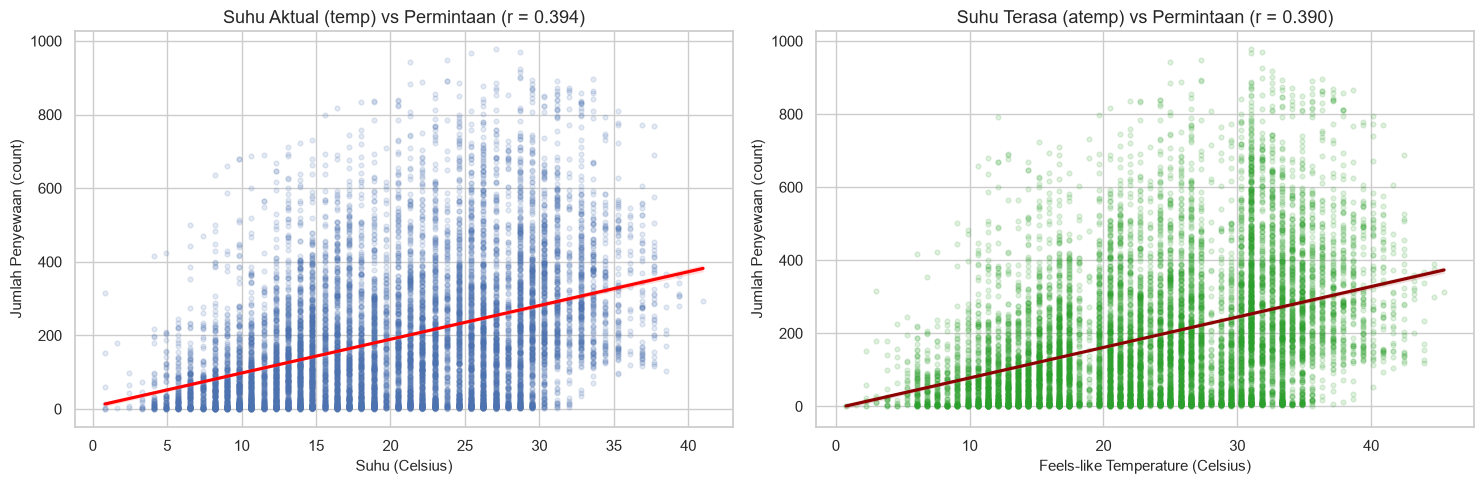

In [13]:
corr_temp = float(eda_df['temp'].corr(eda_df['count']))
corr_atemp = float(eda_df['atemp'].corr(eda_df['count']))
corr_temp_atemp = float(eda_df['temp'].corr(eda_df['atemp']))

print(f'Korelasi Pearson temp vs count  : {corr_temp:.4f}')
print(f'Korelasi Pearson atemp vs count : {corr_atemp:.4f}')
print(f'Korelasi temp vs atemp          : {corr_temp_atemp:.4f}')

eda_df['temp_bin'] = pd.cut(eda_df['temp'], bins=8)
temp_bin_stats = eda_df.groupby('temp_bin', observed=False)['count'].agg(['count', 'mean', 'median']).round(2)
display(temp_bin_stats)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.regplot(
    data=eda_df, x='temp', y='count',
    scatter_kws={'alpha': 0.15, 's': 12}, line_kws={'color': 'red'}, ax=axes[0]
)
axes[0].set_title(f'Suhu Aktual (temp) vs Permintaan (r = {corr_temp:.3f})')
axes[0].set_xlabel('Suhu (Celsius)')
axes[0].set_ylabel('Jumlah Penyewaan (count)')

sns.regplot(
    data=eda_df, x='atemp', y='count',
    scatter_kws={'alpha': 0.15, 's': 12, 'color': '#2ca02c'}, line_kws={'color': 'darkred'}, ax=axes[1]
)
axes[1].set_title(f'Suhu Terasa (atemp) vs Permintaan (r = {corr_atemp:.3f})')
axes[1].set_xlabel('Feels-like Temperature (Celsius)')
axes[1].set_ylabel('Jumlah Penyewaan (count)')

plt.tight_layout()
plt.savefig(FIGURES_DIR / '05_temperature_analysis.png', dpi=150)
plt.show()

## 12. Analisis Hubungan Kelembapan (`humidity`) & Kecepatan Angin (`windspeed`)

Korelasi Pearson humidity vs count  : -0.3174
Korelasi Pearson windspeed vs count : 0.1014
Jumlah observasi humidity == 0      : 22
Jumlah observasi windspeed == 0     : 1313


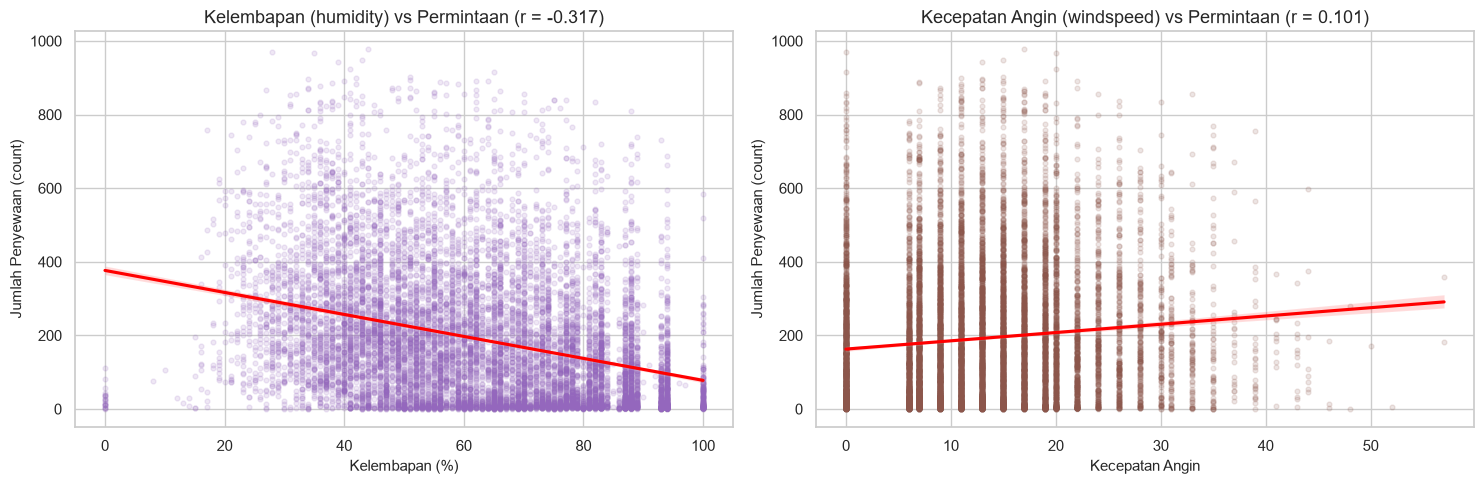

In [14]:
corr_hum = float(eda_df['humidity'].corr(eda_df['count']))
corr_wind = float(eda_df['windspeed'].corr(eda_df['count']))
zero_hum_rows = int((eda_df['humidity'] == 0).sum())
zero_wind_rows = int((eda_df['windspeed'] == 0).sum())

print(f'Korelasi Pearson humidity vs count  : {corr_hum:.4f}')
print(f'Korelasi Pearson windspeed vs count : {corr_wind:.4f}')
print(f'Jumlah observasi humidity == 0      : {zero_hum_rows}')
print(f'Jumlah observasi windspeed == 0     : {zero_wind_rows}')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.regplot(
    data=eda_df, x='humidity', y='count',
    scatter_kws={'alpha': 0.15, 's': 12, 'color': '#9467bd'}, line_kws={'color': 'red'}, ax=axes[0]
)
axes[0].set_title(f'Kelembapan (humidity) vs Permintaan (r = {corr_hum:.3f})')
axes[0].set_xlabel('Kelembapan (%)')
axes[0].set_ylabel('Jumlah Penyewaan (count)')

sns.regplot(
    data=eda_df, x='windspeed', y='count',
    scatter_kws={'alpha': 0.15, 's': 12, 'color': '#8c564b'}, line_kws={'color': 'red'}, ax=axes[1]
)
axes[1].set_title(f'Kecepatan Angin (windspeed) vs Permintaan (r = {corr_wind:.3f})')
axes[1].set_xlabel('Kecepatan Angin')
axes[1].set_ylabel('Jumlah Penyewaan (count)')

plt.tight_layout()
plt.savefig(FIGURES_DIR / '06_humidity_windspeed_analysis.png', dpi=150)
plt.show()

## 13. Visualisasi Matriks Korelasi Keseluruhan & Penyimpanan Ringkasan EDA

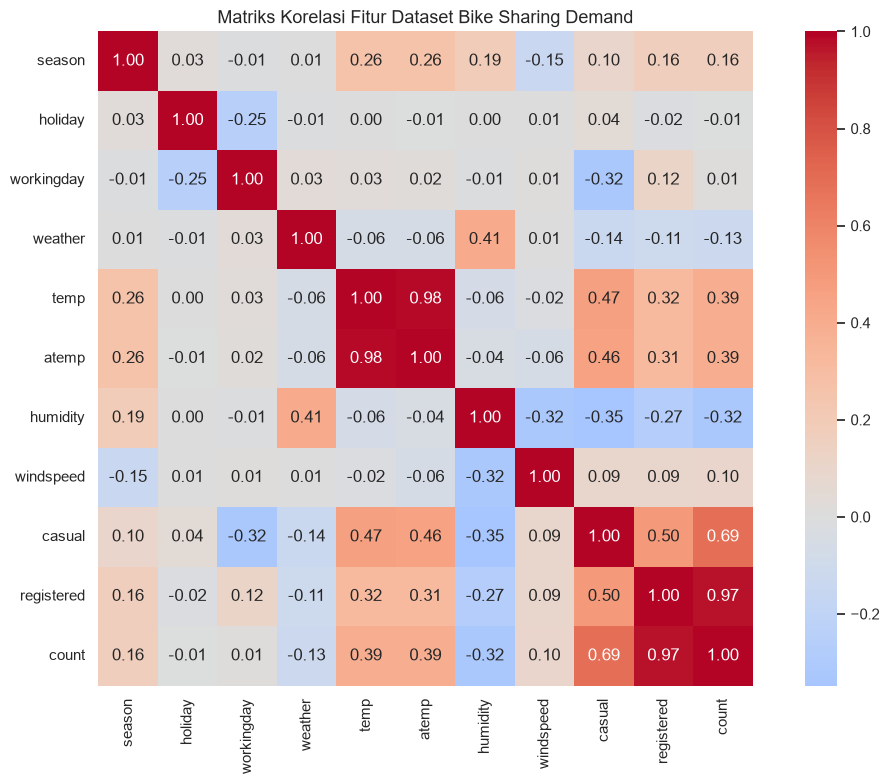

Ringkasan EDA aktual tersimpan di: C:\Users\HS\Desktop\UTS MOSI (TEORI DAN PRAK) - PEMODELAN DAN SIMULASI\bike-dynamics\artifacts\eda_summary.json
{
  "dataset_path": "data\\raw\\train.csv",
  "num_rows": 10886,
  "num_columns": 12,
  "columns": [
    "datetime",
    "season",
    "holiday",
    "workingday",
    "weather",
    "temp",
    "atemp",
    "humidity",
    "windspeed",
    "casual",
    "registered",
    "count"
  ],
  "dtypes": {
    "datetime": "str",
    "season": "int64",
    "holiday": "int64",
    "workingday": "int64",
    "weather": "int64",
    "temp": "float64",
    "atemp": "float64",
    "humidity": "int64",
    "windspeed": "float64",
    "casual": "int64",
    "registered": "int64",
    "count": "int64"
  },
  "missing_values_total": 0,
  "exact_duplicates": 0,
  "timestamp_duplicates": 0,
  "time_range": {
    "start": "2011-01-01 00:00:00",
    "end": "2012-12-19 23:00:00"
  },
  "target_count_stats": {
    "mean": 191.57,
    "median": 145.0,
    "std": 181

In [15]:
numeric_cols = ['season', 'holiday', 'workingday', 'weather', 'temp', 'atemp', 'humidity', 'windspeed', 'casual', 'registered', 'count']
corr_matrix = eda_df[numeric_cols].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Matriks Korelasi Fitur Dataset Bike Sharing Demand')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '07_correlation_heatmap.png', dpi=150)
plt.show()

# Simpan ringkasan hasil inspeksi aktual ke artifacts/eda_summary.json
eda_summary = {
    'dataset_path': str(RAW_DATA_PATH.relative_to(PROJECT_ROOT)),
    'num_rows': int(n_rows),
    'num_columns': int(n_cols),
    'columns': df_raw.columns.tolist(),
    'dtypes': {col: str(dtype) for col, dtype in df_raw.dtypes.items()},
    'missing_values_total': int(df_raw.isnull().sum().sum()),
    'exact_duplicates': exact_duplicates,
    'timestamp_duplicates': timestamp_duplicates,
    'time_range': {
        'start': str(dt_series.min()),
        'end': str(dt_series.max())
    },
    'target_count_stats': {
        'mean': round(float(df_raw['count'].mean()), 2),
        'median': round(float(df_raw['count'].median()), 2),
        'std': round(float(df_raw['count'].std()), 2),
        'min': int(df_raw['count'].min()),
        'max': int(df_raw['count'].max()),
        'skewness': round(count_skew, 4),
        'log1p_skewness': round(log_count_skew, 4)
    },
    'correlations_with_count': {
        'temp': round(corr_temp, 4),
        'atemp': round(corr_atemp, 4),
        'humidity': round(corr_hum, 4),
        'windspeed': round(corr_wind, 4)
    },
    'anomalies_detected': {
        'humidity_zero_rows': zero_hum_rows,
        'windspeed_zero_rows': zero_wind_rows
    }
}

summary_path = ARTIFACTS_DIR / 'eda_summary.json'
with open(summary_path, 'w', encoding='utf-8') as f:
    json.dump(eda_summary, f, indent=2)

print(f'Ringkasan EDA aktual tersimpan di: {summary_path}')
print(json.dumps(eda_summary, indent=2))

## 14. Kesimpulan Awal Exploratory Data Analysis (EDA)

Berdasarkan struktur dataset aktual Kaggle Bike Sharing Demand (`data/raw/train.csv`), poin utama yang menjadi fondasi untuk **Tahap 2 (`02_preprocessing.ipynb`)** dan **Tahap 5 (`05_system_dynamics.ipynb`)** adalah:

1. **Struktur & Kelengkapan Temporal:** Dataset memiliki format deret waktu per jam (`datetime`) pada tanggal **1–19 setiap bulan** (rentang tahun 2011–2012, 10.886 baris × 12 kolom pada distribusi standar Kaggle). Tidak terdapat nilai kosong (*missing values*) maupun baris duplikat, sehingga integritas deret waktu terjaga.
2. **Potensi Data Leakage (`casual` & `registered`):** Variabel target `count` merupakan penjumlahan eksak dari `casual + registered`. Oleh karena itu, kedua kolom tersebut **wajib dikeluarkan dari fitur input** pada tahap preprocessing dan pemodelan Machine Learning.
3. **Distribusi Target (`count`):** Distribusi `count` menceng ke kanan (*right-skewed*) dengan nilai minimum kecil pada dini hari dan lonjakan tajam pada jam sibuk. Transformasi atau algoritma berbasis pohon keputusan (*Random Forest*, *Gradient Boosting*) sangat relevan untuk diuji pada Tahap 3.
4. **Pola Permintaan per Jam & Tipe Hari:** Terdapat perbedaan pola struktural yang sangat kontras antara **hari kerja (`workingday = 1`)** yang membentuk kurva *bimodal* (puncak komuter pagi pukul 08:00 dan sore pukul 17:00–18:00 didominasi pengguna `registered`) dengan **akhir pekan/hari libur (`workingday = 0`)** yang membentuk kurva *unimodal* landai di siang hingga sore hari (pukul 12:00–16:00 dengan kontribusi tinggi pengguna `casual`).
5. **Pengaruh Faktor Meteorologis & Musim:**
   - **Suhu (`temp` & `atemp`)** berkorelasi positif kuat dengan permintaan, namun keduanya memiliki multikolinearitas sangat tinggi sehingga perlu dipertimbangkan saat pemilihan fitur.
   - **Kelembapan (`humidity`)** berkorelasi negatif terhadap jumlah penyewaan, serta perlu pemeriksaan khusus pada baris dengan nilai `humidity == 0` atau `windspeed == 0` sebagai potensi anomali pencatatan sensor.
   - **Cuaca ekstrem (`weather` 3 & 4)** menurunkan permintaan secara drastis dibandingkan cuaca cerah (`weather` 1), yang nantinya akan dijadikan pengali (*weather multiplier*) pada sub-model **System Dynamics**.
6. **Implikasi ke System Dynamics:** Dataset `train.csv` hanya mencatat tingkat permintaan masuk (`count`), dan tidak mencatat secara langsung durasi perjalanan aktual, laju pengembalian sepeda, maupun laju kerusakan armada. Komponen tersebut akan dimodelkan secara transparan melalui persamaan *Stock and Flow* beserta uji sensitivitas parameter pada `05_system_dynamics.ipynb`.